# 04 — Résultats du modèle retenu

Les notebooks 02 et 03 ont fixé les entrées et le modèle, uniquement en validation croisée sur train + val. Ce notebook
fait **la seule évaluation sur le test** :

1. **Entraînement final** de chaque candidat sur train, seuil par tag réglé sur val.
2. **Interprétation** du modèle retenu : quelle source décide pour quel tag.
3. **Résultats sur le test** : métriques globales et par tag, significativité des écarts, comparaison à un LLM.
4. **Analyse d'erreurs et latence.**

| Modèle | Rôle |
|---|---|
| toujours oui | plancher trivial : prédit les 8 tags pour chaque exercice |
| référence | régression logistique sur l'embedding de l'énoncé, meilleur modèle de la partie 1 du notebook 03 |
| concaténation, MLP multimodal, stacking (sources denses) | les alternatives de la partie 2 du notebook 03 |
| **stacking + TF-IDF de l'énoncé** | **le modèle retenu**, celui de `src/` |

In [1]:
import json
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
import yaml
from iterstrat.ml_stratifiers import (
    MultilabelStratifiedKFold,
    MultilabelStratifiedShuffleSplit,
)
from sentence_transformers import SentenceTransformer
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    f1_score,
    hamming_loss,
    jaccard_score,
    precision_recall_fscore_support,
)
from sklearn.model_selection import cross_val_predict
from sklearn.multiclass import OneVsRestClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from torch import nn

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_colwidth", 140)

/Users/ramzi/Documents/illuin-test/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


W1118 11:12:26.253000 85838 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


## Paramètres

Les choix des notebooks 02 et 03, reportés ici.

In [2]:
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks_prod" else Path.cwd()
DATA_PATH = ROOT / "data" / "processed" / "clean.parquet"
EMBEDDINGS_DIR = ROOT / "data" / "embeddings"
LLM_PREDICTIONS_PATH = ROOT / "data" / "llm" / "gemini-3.1-flash-lite__test.jsonl"
CONFIG_PATH = ROOT / "configs" / "stacking.yaml"  # hyperparamètres du code de production

TAGS = ["math", "graphs", "strings", "number theory", "trees", "geometry", "games", "probabilities"]
SEED = 42
N_FOLDS = 5
N_BOOTSTRAP = 1000
THRESHOLD_GRID = np.arange(0.05, 0.96, 0.01)

device = "cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu"
TEXT_MODEL = "sentence-transformers/all-mpnet-base-v2"
CODE_MODEL = "microsoft/unixcoder-base"
CODE_MAX_TOKENS = 1024
DIFFICULTY_BINS = 5
TFIDF_DESC_MIN_DF, TFIDF_DESC_C = 10, 1.0  # notebook 02, section 1

DENSE_BLOCKS = ["description", "input_spec", "notes", "code", "difficulty"]  # notebook 02, synthèse
FINAL_BLOCKS = DENSE_BLOCKS + ["tfidf_desc"]  # notebook 03, section 5.2
CONCAT_C = 1e-3  # notebook 03, section 5.1
MLP_WEIGHT_DECAY = 3.0  # notebook 03, section 5.3

## Données

In [3]:
df = pd.read_parquet(DATA_PATH)
Y = np.array([[tag in tags for tag in TAGS] for tags in df["tags"]], dtype=int)

split = df["split"].to_numpy()
train, val, test = split == "train", split == "val", split == "test"
test_df = df[test]
Y_train, Y_val, Y_test = Y[train], Y[val], Y[test]

EMBEDDING_FILES = {  # calculés au notebook 02
    "description": "all-mpnet-base-v2__prob_desc_description.npz",
    "input_spec": "all-mpnet-base-v2__prob_desc_input_spec.npz",
    "notes": "all-mpnet-base-v2__prob_desc_notes.npz",
    "code": "unixcoder-base__source_code.npz",
}


def load_embeddings(filename: str) -> np.ndarray:
    cache = np.load(EMBEDDINGS_DIR / filename)
    assert np.array_equal(cache["sample_id"], df.index), f"{filename} non aligné : relancer le notebook 02"
    return cache["embeddings"]


blocks = {name: load_embeddings(filename) for name, filename in EMBEDDING_FILES.items()}
blocks["difficulty"] = df[["difficulty"]].to_numpy(dtype=float)
blocks["tfidf_desc"] = df["text_lemma"].to_numpy()

**Contrôle de cohérence avec la production** : les choix reportés ci-dessus doivent être ceux de
`configs/stacking.yaml`, le fichier lu par `python -m src.cli train`. On ne fait que lire le fichier : le notebook ne
dépend pas du code de `src/`.

In [4]:
config = yaml.safe_load(CONFIG_PATH.read_text())
checks = {
    "sources du modèle": (config["model"]["blocks"], FINAL_BLOCKS),
    "C par source": (set(config["model"]["level1"]["C"].values()), {1.0}),  # C=1 pour toutes les sources (notebooks 02-03)
    "tranches de difficulté": (config["features"]["difficulty"]["bins"], DIFFICULTY_BINS),
    "min_df de la TF-IDF": (config["features"]["tfidf_desc"]["min_df"], TFIDF_DESC_MIN_DF),
    "modèle d'énoncé": (config["encoders"]["text_model"], TEXT_MODEL),
    "modèle de code": (config["encoders"]["code_model"], CODE_MODEL),
    "tokens de code": (config["encoders"]["code_max_tokens"], CODE_MAX_TOKENS),
    "folds du stacking": (config["model"]["level2"]["n_folds"], N_FOLDS),
}
for name, (production, notebook) in checks.items():
    assert production == notebook, f"{name} : production {production} ≠ notebook {notebook}"
print(f"{len(checks)} réglages identiques entre ce notebook et configs/stacking.yaml")

8 réglages identiques entre ce notebook et configs/stacking.yaml


## 1. Les modèles

Mêmes définitions qu'au notebook 03, recopiées pour que ce notebook se lise seul.

In [5]:
def logistic(C: float = 1.0) -> OneVsRestClassifier:
    return OneVsRestClassifier(LogisticRegression(C=C, class_weight="balanced", max_iter=2000))


class DifficultyEncoder(BaseEstimator, TransformerMixin):
    """One-hot de la difficulté : tranches de quantiles (apprises au fit) + une colonne « inconnue » (NaN, -1)."""

    def __init__(self, n_bins: int = DIFFICULTY_BINS):
        self.n_bins = n_bins

    def fit(self, X: np.ndarray, y=None) -> "DifficultyEncoder":
        values = X[:, 0]
        known = values[values > 0]  # NaN > 0 est faux : NaN et -1 sont exclus
        self.edges_ = np.quantile(known, np.linspace(0, 1, self.n_bins + 1)[1:-1])
        return self

    def transform(self, X: np.ndarray) -> np.ndarray:
        values = X[:, 0]
        column = np.where(values > 0, np.digitize(np.nan_to_num(values), self.edges_), self.n_bins)
        return np.eye(self.n_bins + 1)[column]


def block_model(name: str):
    """Modèle de niveau 1 d'une source ; sa transformation (tranches, vocabulaire) est apprise au fit."""
    if name == "difficulty":
        return make_pipeline(DifficultyEncoder(), logistic())
    if name == "tfidf_desc":
        return make_pipeline(TfidfVectorizer(stop_words="english", min_df=TFIDF_DESC_MIN_DF, sublinear_tf=True), logistic(TFIDF_DESC_C))
    return logistic()  # embeddings


def logit(p: np.ndarray) -> np.ndarray:
    p = np.clip(p, 1e-6, 1 - 1e-6)
    return np.log(p / (1 - p))


class StackingModel(BaseEstimator):
    """Niveau 1 : un modèle par source. Niveau 2 : par tag, une régression logistique sur les logits out-of-fold."""

    def __init__(self, names: list[str]):
        self.names = names

    def fit(self, sources: dict, Y: np.ndarray) -> "StackingModel":
        inner_folds = MultilabelStratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
        oof = np.stack(
            [cross_val_predict(block_model(n), sources[n], Y, cv=inner_folds, method="predict_proba") for n in self.names], axis=1
        )
        self.block_models_ = {n: block_model(n).fit(sources[n], Y) for n in self.names}
        self.meta_models_ = [LogisticRegression(class_weight="balanced").fit(logit(oof[:, :, k]), Y[:, k]) for k in range(Y.shape[1])]
        return self

    def predict_proba(self, sources: dict) -> np.ndarray:
        probas = np.stack([self.block_models_[n].predict_proba(sources[n]) for n in self.names], axis=1)
        return np.column_stack([meta.predict_proba(logit(probas[:, :, k]))[:, 1] for k, meta in enumerate(self.meta_models_)])


def concat_features(model, sources: dict) -> np.ndarray:
    return np.hstack([model.difficulty_.transform(sources[n]) if n == "difficulty" else sources[n] for n in model.names])


class ConcatModel(BaseEstimator):
    """Sources denses concaténées → standardisation → 8 régressions logistiques."""

    def __init__(self, names: list[str], C: float):
        self.names, self.C = names, C

    def fit(self, sources: dict, Y: np.ndarray) -> "ConcatModel":
        self.difficulty_ = DifficultyEncoder().fit(sources["difficulty"])
        self.model_ = make_pipeline(StandardScaler(), logistic(self.C)).fit(concat_features(self, sources), Y)
        return self

    def predict_proba(self, sources: dict) -> np.ndarray:
        return self.model_.predict_proba(concat_features(self, sources))


class MLP(nn.Module):
    def __init__(self, input_dim: int, dropout: float, hidden: int = 256):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(input_dim, hidden), nn.ReLU(), nn.Dropout(dropout), nn.Linear(hidden, len(TAGS)))

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.net(x)


def train_mlp(X, Y, X_stop, Y_stop, lr, weight_decay, dropout, seed, max_epochs=200, patience=15) -> MLP:
    """Réseau à son epoch de loss minimale sur X_stop (early stopping)."""
    torch.manual_seed(seed)
    X, Y = torch.tensor(X, dtype=torch.float32), torch.tensor(Y, dtype=torch.float32)
    X_stop, Y_stop = torch.tensor(X_stop, dtype=torch.float32), torch.tensor(Y_stop, dtype=torch.float32)
    model = MLP(X.shape[1], dropout)
    positives = Y.sum(dim=0).clamp(min=1)
    loss_fn = nn.BCEWithLogitsLoss(pos_weight=(len(Y) - positives) / positives)
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)

    best_loss, best_state, best_epoch = float("inf"), None, 0
    for epoch in range(max_epochs):
        model.train()
        for batch in torch.randperm(len(X)).split(64):
            optimizer.zero_grad()
            loss_fn(model(X[batch]), Y[batch]).backward()
            optimizer.step()
        model.eval()
        with torch.no_grad():
            stop_loss = loss_fn(model(X_stop), Y_stop).item()
        if stop_loss < best_loss:
            best_loss, best_epoch = stop_loss, epoch
            best_state = {k: v.clone() for k, v in model.state_dict().items()}
        if epoch - best_epoch >= patience:
            break
    model.load_state_dict(best_state)
    return model


class MultimodalMLP(BaseEstimator):
    """Sources denses concaténées → standardisation → moyenne de `n_seeds` MLP."""

    def __init__(self, names: list[str], weight_decay: float, lr: float = 3e-3, dropout: float = 0.5, n_seeds: int = 5):
        self.names, self.weight_decay, self.lr, self.dropout, self.n_seeds = names, weight_decay, lr, dropout, n_seeds

    def fit(self, sources: dict, Y: np.ndarray) -> "MultimodalMLP":
        self.difficulty_ = DifficultyEncoder().fit(sources["difficulty"])
        self.scaler_ = StandardScaler().fit(concat_features(self, sources))
        X = self.scaler_.transform(concat_features(self, sources))
        splitter = MultilabelStratifiedShuffleSplit(n_splits=1, test_size=0.15, random_state=SEED)
        fit_idx, stop_idx = next(splitter.split(X, Y))
        params = {"lr": self.lr, "weight_decay": self.weight_decay, "dropout": self.dropout}
        self.nets_ = [train_mlp(X[fit_idx], Y[fit_idx], X[stop_idx], Y[stop_idx], seed=s, **params) for s in range(self.n_seeds)]
        return self

    def predict_proba(self, sources: dict) -> np.ndarray:
        X = torch.tensor(self.scaler_.transform(concat_features(self, sources)), dtype=torch.float32)
        with torch.no_grad():
            return np.mean([torch.sigmoid(net.eval()(X)).numpy() for net in self.nets_], axis=0)


class DescriptionOnly(BaseEstimator):
    """La référence de la partie 1 du notebook 03, avec la même interface que les autres modèles."""

    def fit(self, sources: dict, Y: np.ndarray) -> "DescriptionOnly":
        self.model_ = logistic().fit(sources["description"], Y)
        return self

    def predict_proba(self, sources: dict) -> np.ndarray:
        return self.model_.predict_proba(sources["description"])

## 2. Entraînement final

Comme au notebook 03 : entraînement sur train, seuil par tag réglé sur val (le seuil qui maximise le F1), une seule
évaluation sur test.

In [6]:
def tune_thresholds(y_true: np.ndarray, proba: np.ndarray) -> np.ndarray:
    """Pour chaque tag, le seuil qui maximise le F1 sur val."""
    thresholds = []
    for k in range(y_true.shape[1]):
        f1s = [f1_score(y_true[:, k], proba[:, k] >= t, zero_division=0) for t in THRESHOLD_GRID]
        thresholds.append(THRESHOLD_GRID[np.argmax(f1s)])
    return np.array(thresholds)


BEST_MODEL = "stacking + tfidf_desc (retenu)"
models = {
    "référence (énoncé seul)": DescriptionOnly(),
    "concaténation": ConcatModel(DENSE_BLOCKS, CONCAT_C),
    "MLP multimodal": MultimodalMLP(DENSE_BLOCKS, weight_decay=MLP_WEIGHT_DECAY),
    "stacking (sources denses)": StackingModel(DENSE_BLOCKS),
    BEST_MODEL: StackingModel(FINAL_BLOCKS),
}


def rows(sources: dict, mask: np.ndarray) -> dict:
    return {name: block[mask] for name, block in sources.items()}


train_blocks, val_blocks, test_blocks = rows(blocks, train), rows(blocks, val), rows(blocks, test)
predictions = {"toujours oui": np.ones_like(Y_test)}
thresholds = {}
for name, model in models.items():
    model.fit(train_blocks, Y_train)
    thresholds[name] = tune_thresholds(Y_val, model.predict_proba(val_blocks))
    predictions[name] = (model.predict_proba(test_blocks) >= thresholds[name]).astype(int)
print("Seuils du modèle retenu :", dict(zip(TAGS, thresholds[BEST_MODEL].round(2).tolist())))

Seuils du modèle retenu : {'math': 0.52, 'graphs': 0.76, 'strings': 0.76, 'number theory': 0.79, 'trees': 0.92, 'geometry': 0.8, 'games': 0.92, 'probabilities': 0.93}


### Quelle source décide pour quel tag ?

Les poids du niveau 2 du stacking : un poids élevé signifie que le tag suit surtout ce bloc.

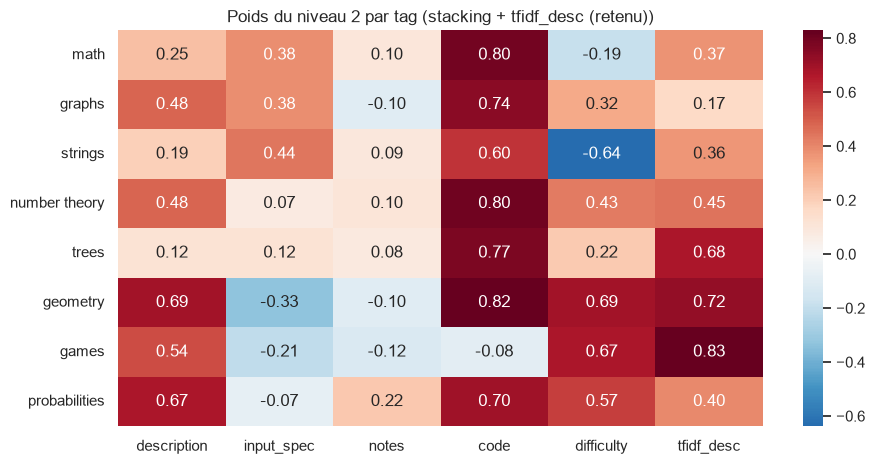

In [7]:
best = models[BEST_MODEL]
weights = pd.DataFrame([meta.coef_[0] for meta in best.meta_models_], index=TAGS, columns=best.names)
fig, ax = plt.subplots(figsize=(9.5, 4.8))
sns.heatmap(weights, annot=True, fmt=".2f", cmap="RdBu_r", center=0, ax=ax)
ax.set(title=f"Poids du niveau 2 par tag ({BEST_MODEL})")
plt.tight_layout()
plt.show()

## 3. Résultats sur le test, et comparaison à un LLM

**LLM zero-shot** : `gemini-3.1-flash-lite` reçoit les mêmes colonnes (énoncé, spécification d'entrée, notes,
difficulté, code) et la définition des 8 tags, et répond en JSON. Aucun entraînement. Ses prédictions sur le test ont
été calculées une fois et sont relues depuis `data/llm/` (aucun appel ici).

In [8]:
LLM = "LLM gemini-3.1-flash-lite (zero-shot)"
if LLM_PREDICTIONS_PATH.exists():
    with LLM_PREDICTIONS_PATH.open() as f:
        llm_tags = {record["sample_id"]: set(record["tags"]) for record in map(json.loads, f)}
    # Un exemple sans réponse compte comme « aucun tag »
    predictions[LLM] = np.array([[tag in llm_tags.get(sid, set()) for tag in TAGS] for sid in test_df.index], dtype=int)
    print(f"Prédictions LLM : {len(llm_tags)} / {len(test_df)} exemples")


def global_metrics(y_true: np.ndarray, y_pred: np.ndarray) -> dict[str, float]:
    return {
        "micro_f1": f1_score(y_true, y_pred, average="micro", zero_division=0),
        "macro_f1": f1_score(y_true, y_pred, average="macro", zero_division=0),
        "hamming_loss": hamming_loss(y_true, y_pred),
        "jaccard": jaccard_score(y_true, y_pred, average="samples", zero_division=1),
    }


pd.DataFrame({name: global_metrics(Y_test, pred) for name, pred in predictions.items()}).T.round(3)

Prédictions LLM : 726 / 726 exemples


,micro_f1,macro_f1,hamming_loss,jaccard
toujours oui,0.158,0.149,0.914,0.086
référence (énoncé seul),0.554,0.612,0.083,0.532
concaténation,0.618,0.642,0.074,0.588
MLP multimodal,0.610,0.621,0.075,0.577
stacking (sources denses),0.622,0.646,0.074,0.602
stacking + tfidf_desc (retenu),0.627,0.647,0.072,0.600
LLM gemini-3.1-flash-lite (zero-shot),0.674,0.753,0.067,0.581


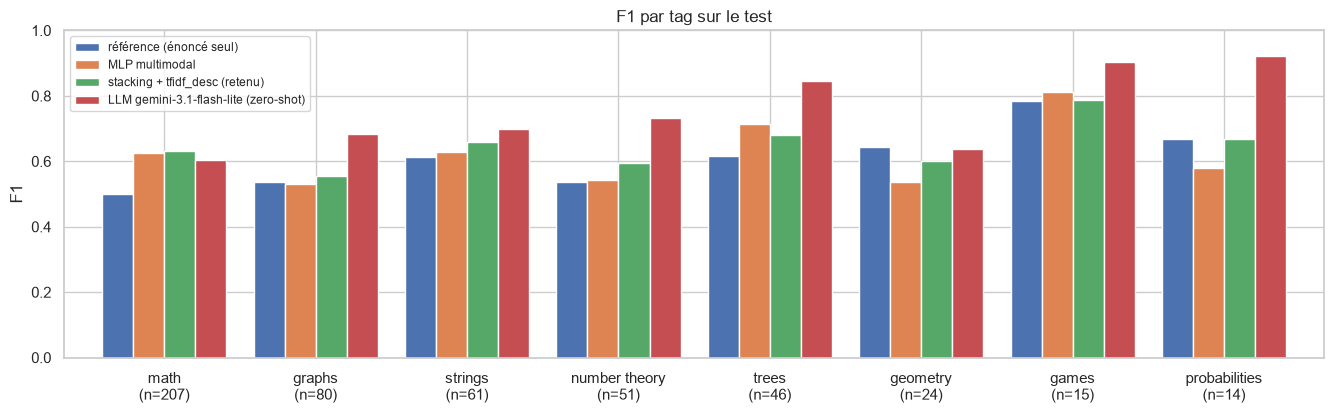

In [9]:
def f1_per_tag(pred: np.ndarray) -> np.ndarray:
    return precision_recall_fscore_support(Y_test, pred, zero_division=0)[2]


key_models = ["référence (énoncé seul)", "MLP multimodal", BEST_MODEL] + ([LLM] if LLM in predictions else [])
f1_by_tag = pd.DataFrame({name: f1_per_tag(predictions[name]) for name in key_models}, index=TAGS)
support = Y_test.sum(axis=0)

fig, ax = plt.subplots(figsize=(13.5, 4.3))
f1_by_tag.plot.bar(ax=ax, rot=0, width=0.82)
ax.set(title="F1 par tag sur le test", ylabel="F1", ylim=(0, 1))
ax.set_xticklabels([f"{t}\n(n={n})" for t, n in zip(TAGS, support)])
ax.legend(loc="upper left", fontsize=8.5)
plt.tight_layout()
plt.show()

In [10]:
# Détail du meilleur modèle entraîné, comparé au plancher « toujours oui »
precision, recall, f1, _ = precision_recall_fscore_support(Y_test, predictions[BEST_MODEL], zero_division=0)
trivial_f1 = f1_per_tag(predictions["toujours oui"])
pd.DataFrame(
    {"précision": precision, "rappel": recall, "f1": f1, "support": support, "f1 toujours oui": trivial_f1, "gain (x)": f1 / trivial_f1},
    index=TAGS,
).round(2)

,précision,rappel,f1,support,f1 toujours oui,gain (x)
math,0.57,0.71,0.63,207,0.44,1.42
graphs,0.52,0.60,0.55,80,0.20,2.80
strings,0.56,0.80,0.66,61,0.16,4.24
number theory,0.55,0.65,0.59,51,0.13,4.53
trees,0.67,0.70,0.68,46,0.12,5.71
geometry,0.46,0.88,0.60,24,0.06,9.38
games,0.72,0.87,0.79,15,0.04,19.46
probabilities,0.62,0.71,0.67,14,0.04,17.62


**Significativité** : même bootstrap apparié qu'au notebook 03.

In [11]:
def bootstrap_diff(pred_a: np.ndarray, pred_b: np.ndarray) -> dict[str, float]:
    rng = np.random.default_rng(SEED)
    diffs = []
    for _ in range(N_BOOTSTRAP):
        idx = rng.integers(0, len(Y_test), len(Y_test))
        diffs.append(
            f1_score(Y_test[idx], pred_a[idx], average="macro", zero_division=0)
            - f1_score(Y_test[idx], pred_b[idx], average="macro", zero_division=0)
        )
    low, high = np.percentile(diffs, [2.5, 97.5])
    return {"écart moyen": np.mean(diffs), "IC 2,5 %": low, "IC 97,5 %": high, "P(a > b)": np.mean(np.array(diffs) > 0)}


pairs = [
    (BEST_MODEL, "référence (énoncé seul)"),
    (BEST_MODEL, "concaténation"),
    (BEST_MODEL, "stacking (sources denses)"),
    (BEST_MODEL, "MLP multimodal"),
] + ([(LLM, BEST_MODEL)] if LLM in predictions else [])
pd.DataFrame({f"{a} − {b}": bootstrap_diff(predictions[a], predictions[b]) for a, b in pairs}).T.round(3)

,écart moyen,"IC 2,5 %","IC 97,5 %",P(a > b)
stacking + tfidf_desc (retenu) − référence (énoncé seul),0.035,-0.001,0.073,0.974
stacking + tfidf_desc (retenu) − concaténation,0.005,-0.023,0.032,0.658
stacking + tfidf_desc (retenu) − stacking (sources denses),0.001,-0.023,0.028,0.521
stacking + tfidf_desc (retenu) − MLP multimodal,0.026,-0.004,0.053,0.957
LLM gemini-3.1-flash-lite (zero-shot) − stacking + tfidf_desc (retenu),0.108,0.070,0.151,1.000


## 4. Analyse d'erreurs et latence

In [12]:
pred = predictions[BEST_MODEL]
display(
    pd.DataFrame(
        {"faux positifs": ((pred == 1) & (Y_test == 0)).sum(axis=0), "faux négatifs": ((pred == 0) & (Y_test == 1)).sum(axis=0), "support": support},
        index=TAGS,
    )
)

if LLM in predictions:
    k = TAGS.index("math")
    disagree = predictions[LLM][:, k] != pred[:, k]
    stacking_right = (pred[disagree, k] == Y_test[disagree, k]).sum()
    print(f"Désaccords sur 'math' : {disagree.sum()} | le stacking a raison {stacking_right} fois, le LLM {disagree.sum() - stacking_right} fois")

for kind, tag in [("faux négatifs", "math"), ("faux positifs", "graphs")]:
    k = TAGS.index(tag)
    mask = (pred[:, k] == 0) & (Y_test[:, k] == 1) if kind == "faux négatifs" else (pred[:, k] == 1) & (Y_test[:, k] == 0)
    print(f"\n=== {tag} : {kind} ===")
    for sid, row in test_df[mask].head(2).iterrows():
        print(f"  [{sid}] tags={list(row['tags'])} -> {row['prob_desc_description'][:150]}...")

,faux positifs,faux négatifs,support
math,112,60,207
graphs,45,32,80
strings,39,12,61
number theory,27,18,51
trees,16,14,46
geometry,25,3,24
games,5,2,15
probabilities,6,4,14


Désaccords sur 'math' : 168 | le stacking a raison 110 fois, le LLM 58 fois

=== math : faux négatifs ===
  [40] tags=['number theory', 'bitmasks', 'math', 'strings'] -> You are given two strings $$$s$$$ and $$$t$$$, both consisting of exactly $$$k$$$ lowercase Latin letters, $$$s$$$ is lexicographically less than $$$t...
  [161] tags=['implementation', 'probabilities', 'math'] -> Vasya and Kolya play a game with a string, using the following rules. Initially, Kolya creates a string s, consisting of small English letters, and un...

=== graphs : faux positifs ===
  [64] tags=['dfs and similar'] -> Fox Ciel is playing a mobile puzzle game called "Two Dots". The basic levels are played on a board of size n × m cells, like this:Each cell contains a...
  [81] tags=['implementation'] -> The research center Q has developed a new multi-core processor. The processor consists of n cores and has k cells of cache memory. Consider the work o...


**Latence** : temps pour prédire un exercice de bout en bout (3 encodages Sentence-BERT, 1 encodage UniXcoder,
TF-IDF, stacking et seuils), à partir des textes déjà normalisés. Contrainte du sujet : < 10 s par exemple.

In [13]:
start = time.perf_counter()
text_encoder = SentenceTransformer(TEXT_MODEL, device=device)
code_encoder = SentenceTransformer(CODE_MODEL, device=device)
code_encoder.max_seq_length = CODE_MAX_TOKENS
print(f"Chargement des encodeurs : {time.perf_counter() - start:.1f} s (une seule fois)")


def encode_text(text: str) -> np.ndarray:
    return text_encoder.encode([text], normalize_embeddings=True)


def predict_one(row: pd.Series) -> np.ndarray:
    example = {
        "description": encode_text(row["text_clean"]),
        "input_spec": encode_text(row["input_spec_clean"]),
        "notes": encode_text(row["notes_clean"]),
        "code": code_encoder.encode([row["source_code"]], normalize_embeddings=True),
        "difficulty": np.array([[row["difficulty"]]], dtype=float),
        "tfidf_desc": np.array([row["text_lemma"]]),
        "tfidf_code": np.array([row["source_code"]]),
    }
    return (best.predict_proba(example) >= thresholds[BEST_MODEL]).astype(int)


predict_one(test_df.iloc[0])  # échauffement
latencies = []
for i in range(50):
    start = time.perf_counter()
    predict_one(test_df.iloc[i])
    latencies.append(time.perf_counter() - start)
print(f"Latence par exemple : médiane {np.median(latencies) * 1000:.0f} ms, max {np.max(latencies) * 1000:.0f} ms")

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 13545.82it/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 70418.16it/s]

Chargement des encodeurs : 2.0 s (une seule fois)


Latence par exemple : médiane 59 ms, max 121 ms


## Synthèse

1. **La multimodalité paie** : passer de l'énoncé seul au stacking retenu (embeddings de l'énoncé, de la spécification,
   des notes et du code, difficulté, TF-IDF de l'énoncé) améliore le Macro-F1 sur le test (section 3).
2. **Le code (UniXcoder) est la deuxième source la plus utile** après l'énoncé (ablation du notebook 02), et il pèse
   fortement au niveau 2, en particulier pour `math`, dont le raisonnement se lit dans la solution plutôt que dans
   l'énoncé (section 2).
3. **Les trois combinaisons de sources se tiennent de près sur le test** ; le stacking retenu est en tête. Le MLP
   multimodal ne fait pas mieux que les modèles linéaires, comme en validation croisée au notebook 03.
4. **LLM zero-shot** : meilleur en Macro-F1, surtout sur les tags rares et conceptuels, mais il sur-étiquette et fait
   moins bien que le stacking sur `math`, dont la convention d'annotation de Codeforces s'apprend des données.
5. **Contraintes respectées** : modèle local, déterministe, gratuit à l'usage, et prédiction en moins de 100 ms par
   exemple, très loin de la limite de 10 s.

**Pistes** : retirer `notes` (un encodage de moins à l'inférence) ; tester la TF-IDF non lemmatisée (notebook 02) ;
régler les seuils sur les prédictions out-of-fold (~4 100 exemples) plutôt que sur val seul (725), pour stabiliser
les tags rares.